In [3]:
import scanpy as sc
import pandas as pd
import numpy as npqq
import seaborn as sns
from matplotlib import rcParams
import matplotlib.pyplot as plt

# Code to generate annotations for cell types with marker genes

In [4]:
b_markers=['MS4A1','CD19','MME','CD24','CD27','AIM2','ZEB2','FAS','IL4R','FCER2','CD69','FOS','MKI67','PRDM1','IGHD','IGHG1','IGHA2','IGHE'] #SLAM7
T_markers_4=['CD8A','CD8B','SOX4','SELL','CCR7','ITGB1','ITGA4','FAS','GZMK','GZMA','GZMB','IL2RA','KLRF1','KLRB1','KLRD1','ISG15','MX1','FOXP3']
T_markers_8=['CD8A','CD8B','SOX4','LEF1','SELL','CCR7','ITGB1','ITGA4','FAS','GZMK','GZMA','GZMB','KLRF1','KLRB1','KLRD1','KLRC2','TRAC','TRDC','TRGC1','TRDV1','TRDV2','ISG15','MX1']
nk=['CD3E','CD3D','NCAM1','FCGR3A','KLRC1','KLRC2','FCER1G','GZMB','GZMK','MX1','MKI67']
mono=['S100A8','S100A9','CD14','VCAN','MX1','ISG15','IFI44L','NFKBIA','IL1B','CCL3','SOD2','CD74','FCGR3A','CDKN1C','LST1','C1QA','C1QB','CD68']
dc=['CST3','CD163','VCAN','CD14','CD1C','HLA-DRA','ISG15','MX1','IFI44L','CLEC9A','C1orf54','AXL','SIGLEC6','S100A10','SPI1','ITM2C','IL3RA','IRF8','PLAC8']
other=['HBB','CD34','CD38','PTPRC','DNTT','PF4']


lymph=['CD4','CD40LG','CD8A','CD8B','CCR7','IL7R','TNFRSF4','ITGB1',
                         'RTKN2','FOXP3','PRF1','GZMH','GZMB','GZMK','KLRB1','GNLY','NKG7','FCGR3A',
                         'TCL1A','BANK1','MZB1','FCRL5','MS4A1','CD79A','SOX4','DNTT','PF4']
mye=['CD14','FCGR3A','C1QA','CLEC10A','CLEC9A','LILRA4']

## read in Data

In [5]:
adata=sc.read_h5ad('/gstore/data/ctgbioinfo/gordom14/ICC/data/current_objects/jan2025/MultiVI_posttraining_RNA_Celltypist_VaryingClusteringResolution.h5ad')
# basic normalization of RNA
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

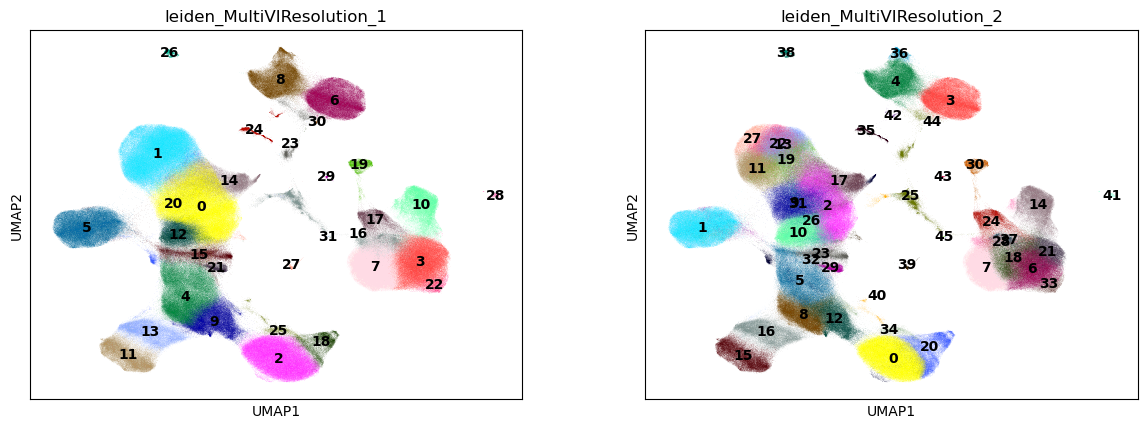

In [4]:
sc.pl.umap(adata, color=['leiden_MultiVIResolution_1','leiden_MultiVIResolution_2'],legend_loc='on data')

## Some basic metrics to establish cells that should be filtered


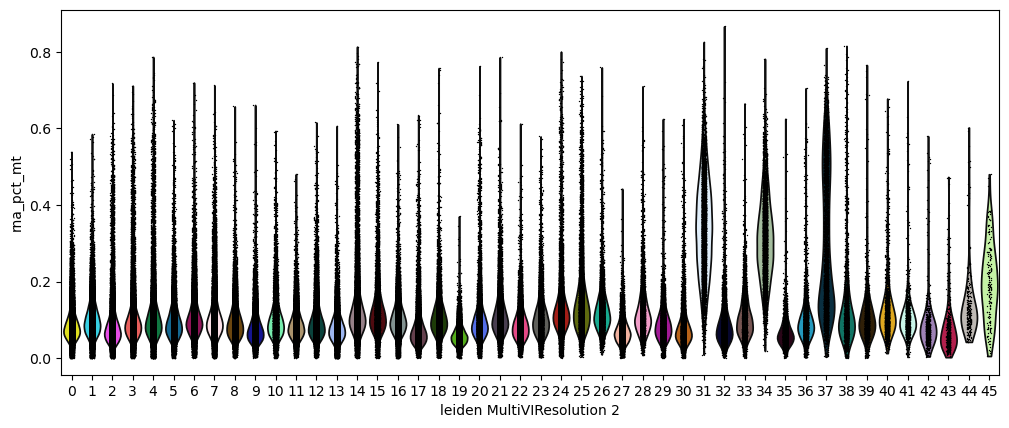

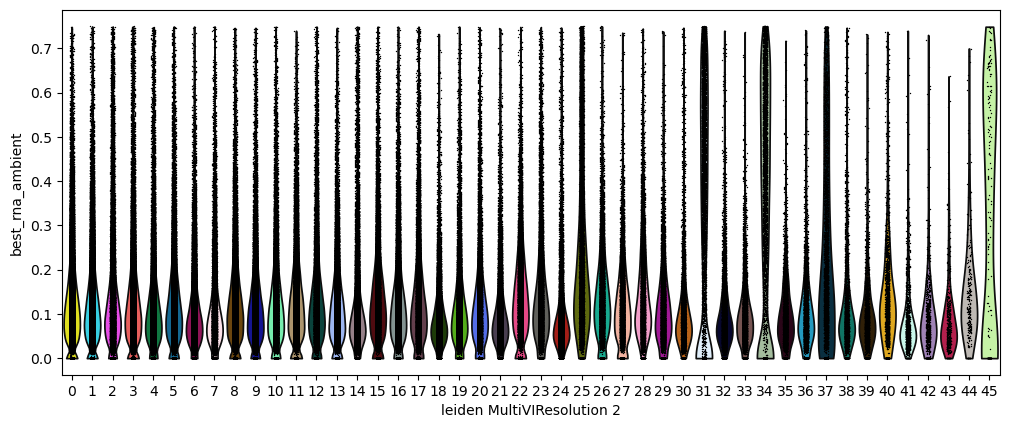

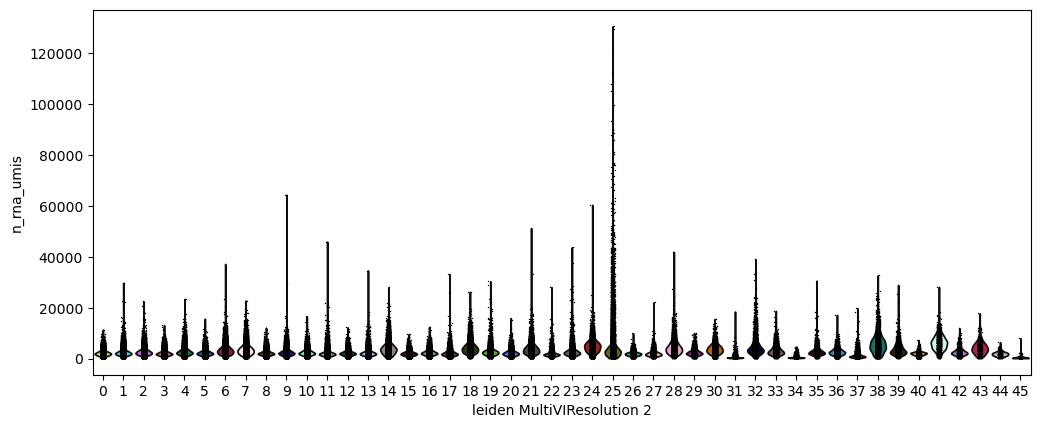

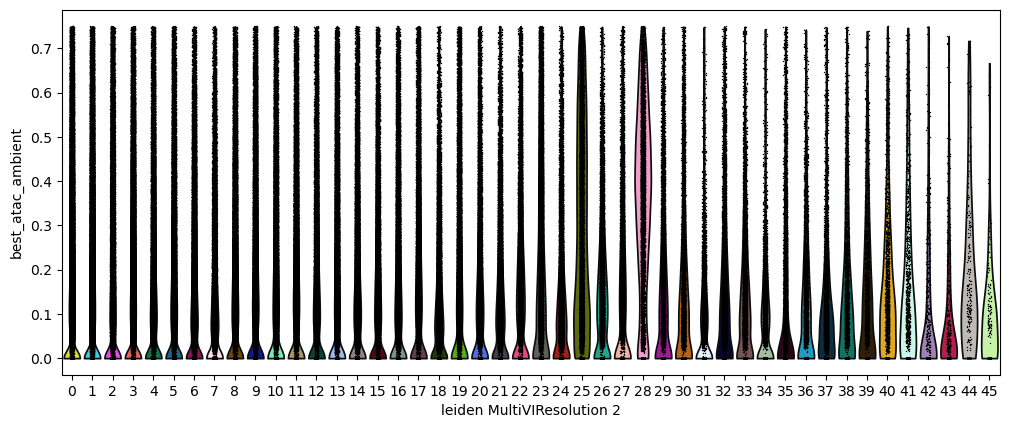

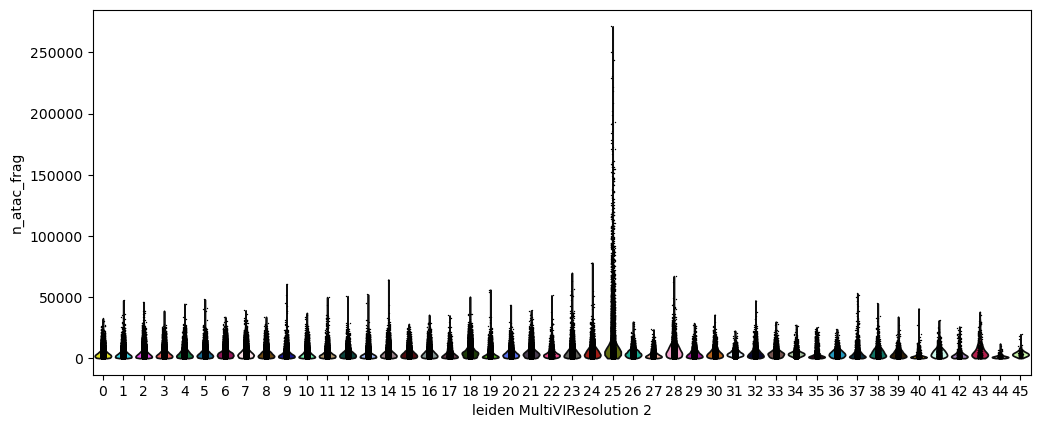

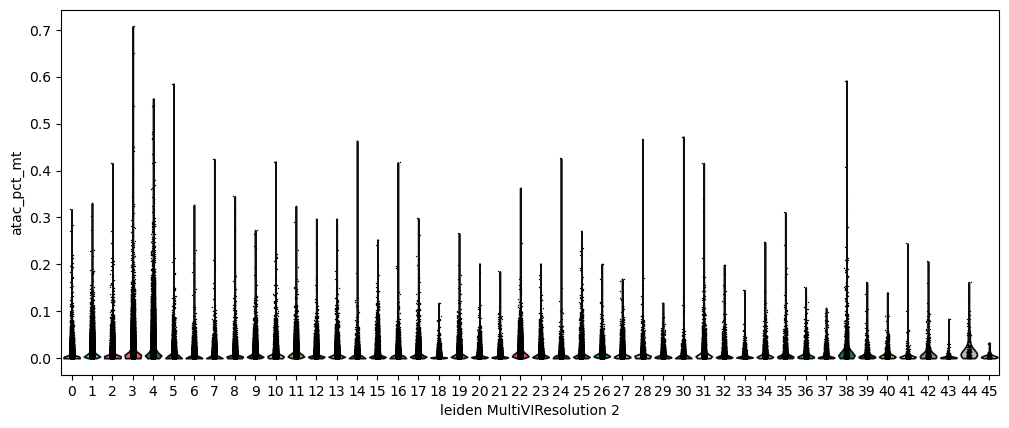

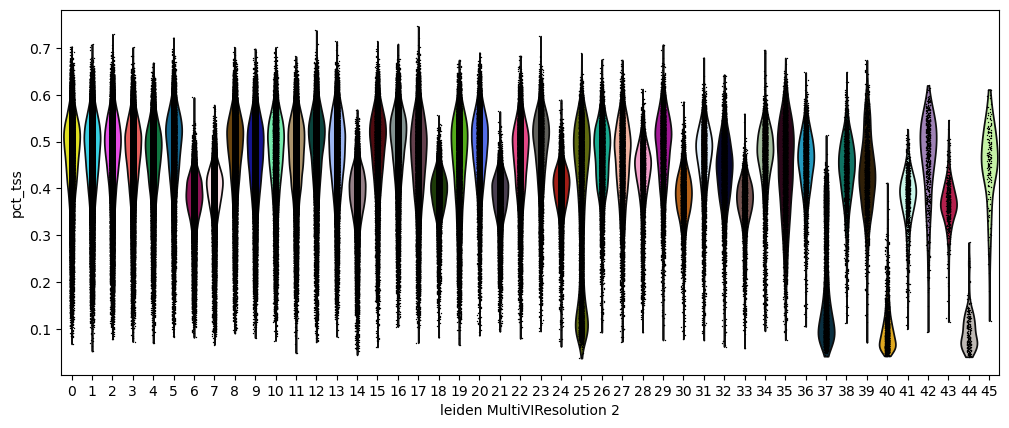

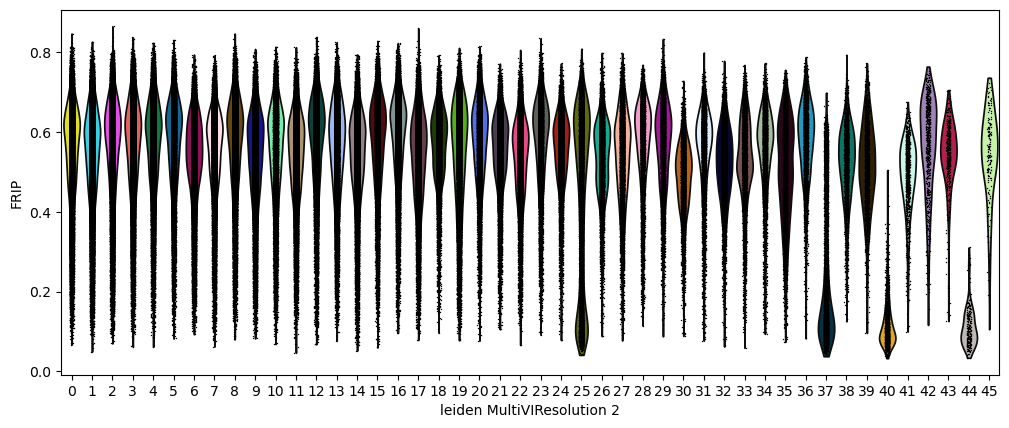

In [5]:
rcParams["figure.figsize"] = (10,5)
sc.pl.violin(adata,'rna_pct_mt', groupby='leiden_MultiVIResolution_2')
sc.pl.violin(adata,'best_rna_ambient', groupby='leiden_MultiVIResolution_2')
sc.pl.violin(adata,'n_rna_umis', groupby='leiden_MultiVIResolution_2')
sc.pl.violin(adata,'best_atac_ambient', groupby='leiden_MultiVIResolution_2')
sc.pl.violin(adata,'n_atac_frag', groupby='leiden_MultiVIResolution_2')
sc.pl.violin(adata,'atac_pct_mt', groupby='leiden_MultiVIResolution_2')
sc.pl.violin(adata,'pct_tss', groupby='leiden_MultiVIResolution_2')
sc.pl.violin(adata,'FRIP', groupby='leiden_MultiVIResolution_2')

In [7]:
# clusters with lower quality scores
qc_removal_basic_metrics=['25','28','31','34','37','40','44','45']

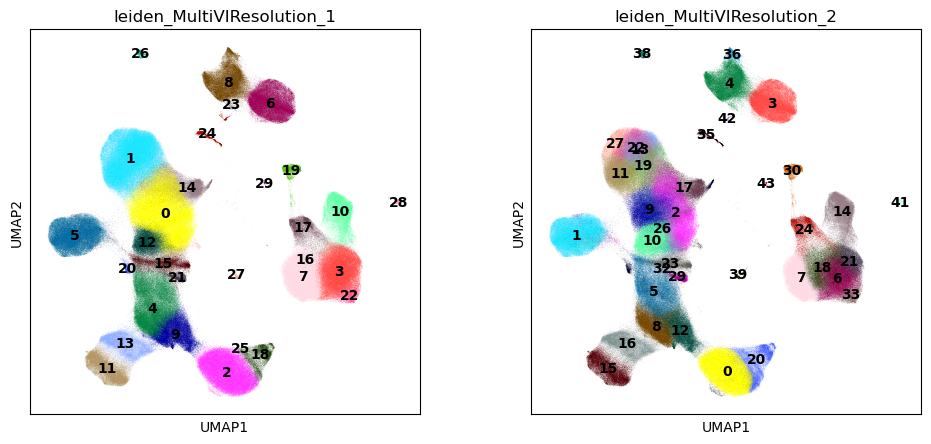

In [ ]:
rcParams["figure.figsize"] = (5,5)

sc.pl.umap(adata[-adata.obs['leiden_MultiVIResolution_2'].isin(qc_removal_basic_metrics)], color=['leiden_MultiVIResolution_1','leiden_MultiVIResolution_2'],legend_loc='on data')

### check a few remaining small clusters to determine if they might be debris

In [9]:
print(adata[adata.obs['leiden_MultiVIResolution_2'].isin( ['35'])].obs.best_sample.value_counts())

best_sample
CUPP_311    2345
CUPP_301    1709
MIB_081        7
MIB_083        6
_2716          3
_4712          2
_4193          2
_0267          1
_3006          1
_1390          1
_3753          1
_3352          1
Name: count, dtype: int64


In [10]:
print(adata[adata.obs['leiden_MultiVIResolution_2'].isin( ['42'])].obs.best_sample.value_counts())

best_sample
CUPP_311    508
CUPP_301    171
_3753         8
MIB_014       2
MIB_081       2
CUPP_361      1
CUPP_491      1
MIB_097       1
_0963         1
_1947         1
_4560         1
_4712         1
Name: count, dtype: int64


In [12]:
print(adata[adata.obs['leiden_MultiVIResolution_2'].isin( ['43'])].obs.best_sample.value_counts())

best_sample
CUPP_311    356
CUPP_301    139
_4712         1
Name: count, dtype: int64


In [11]:
adata[adata.obs.best_sample.isin(['CUPP_311','CUPP_301'])].obs.Pool.value_counts()

Pool
XX22    3380
XX12    2396
Name: count, dtype: int64

In [14]:
# remove these since likely some artifact of these donors 
qc_filter_cells=['25','28','31','34','37','40','44','45','35','42','43']
                      

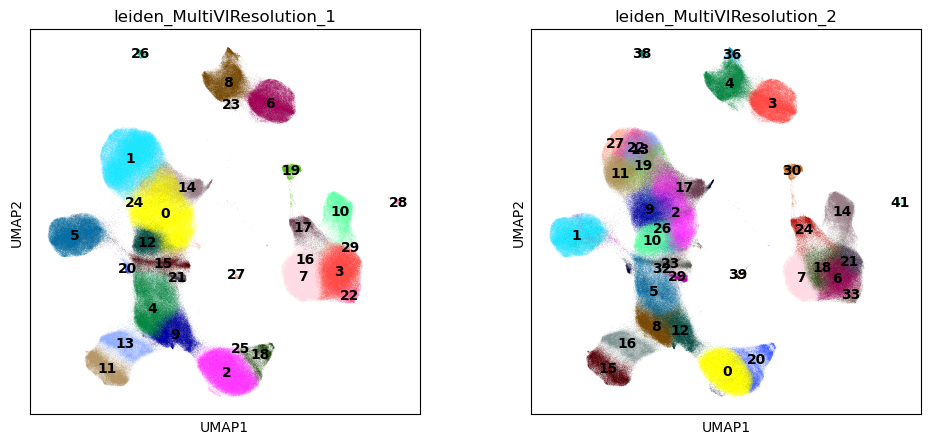

In [15]:
sc.pl.umap(adata[-adata.obs['leiden_MultiVIResolution_2'].isin(qc_filter_cells)], color=['leiden_MultiVIResolution_1','leiden_MultiVIResolution_2'],legend_loc='on data')

## QC filter cells

In [7]:
# remove these since likely some artifact of these donors 
qc_filter_cells=['25','28','31','34','37','40','44','45','35','42','43']

## find L0 markers

In [ ]:
lymph_order=['11','13','19','22','27','2','9','10','26', '17',
             '1','23','12','8','16','5',
             '15','20','0',
             '3','4','38','36',
             '29','32']
mye_order=['6', '7','33','21','18','14',   '24',  '41', '30','39']

In [22]:
print(qc_filter_cells)
print(sorted(['11', '13', '19', '22', '27', '2', '9', '10', '26', '17', '1', '23', 
             '12', '8', '16', '5', '15', '20', '0', '3', '4', '38', '36', '29', 
             '32', '6', '7', '33', '21', '18', '14', '24', '41', '30']))
print(sorted(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10',
               '11', '12', '13', '14', '15', '16', '17', '18', '19', 
               '20', '21', '22', '23', '24', '26', '27', '29', '30', 
               '32', '33', '36', '38', '39', '41']))


['25', '28', '31', '34', '37', '40', '44', '45', '35', '42', '43']
['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '26', '27', '29', '3', '30', '32', '33', '36', '38', '4', '41', '5', '6', '7', '8', '9']
['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '26', '27', '29', '3', '30', '32', '33', '36', '38', '39', '4', '41', '5', '6', '7', '8', '9']


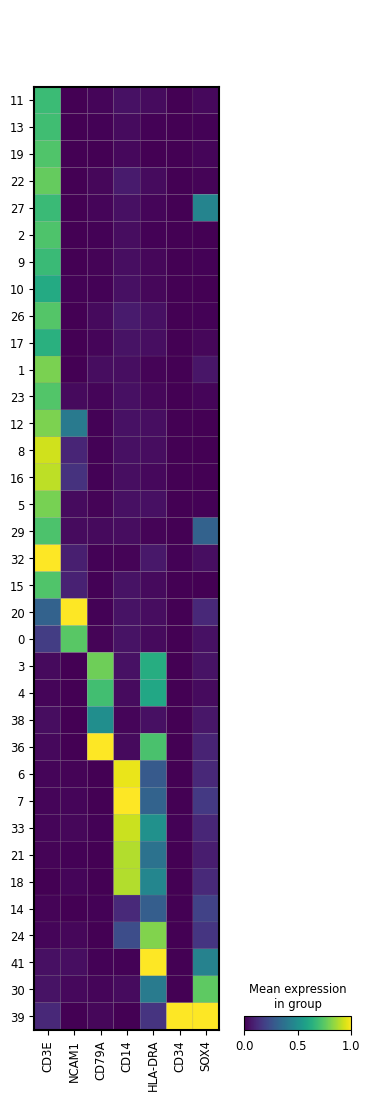

In [24]:
#cell_order=['T','NK','B','Monocyte','DC','Progen']
lymph_order=['11','13','19','22','27','2','9','10','26', '17',
             '1','23','12','8','16','5',
             '29','32',
             '15','20','0',
             '3','4','38','36']
mye_order=['6', '7','33','21','18','14',   '24',  '41', '30','39']
all_order=lymph_order+mye_order
mp=sc.pl.matrixplot(adata[-adata.obs['leiden_MultiVIResolution_2'].isin( qc_filter_cells)],
                        ['CD3E','NCAM1','CD79A','CD14','HLA-DRA','CD34','SOX4'], gene_symbols='name', 
                        groupby='leiden_MultiVIResolution_2',standard_scale='var',
                        categories_order=all_order,
                        return_fig=True)
mp.show()

In [25]:
## manual Leiden_2
L0_cells_R2={
    '0': "NK",
    '1': "T",
    '2': "T",
    '3': "B",
    '4':"B",
    '5':"T",
    '6':"Monocyte",
    '7':"Monocyte",
    '8':"T",
    '9':"T",
    '10':"T",
    '11':"T",
    '12':"T",
    '13':"T",
    '14':"Monocyte",
    '15':"T",
    '16':"T",
    '17':"T",
    '18':"Monocyte",
    '19':"T",
    '20':"NK",
    '21':"Monocyte",
    '22':"T",
    '23':'T',
    '24':'DC',
    '25':"25",
    '26':'T',
    '27':'T',
    '28':'28',
    '29':'T',
    '30':"DC",
    '31':'T',
    '32':'T',
    '33':'Monocyte',
    '34':'34',
    '35':'35',
    '36':'B',
    '37':'37',
    '38':'B',
    '39':'Progen',
    '40':'40',
    '41':'DC',
    '42':'42',
    '43':'43',
    '44':'44',
    '45':'45'

}
adata.obs['L0_manual']=[ L0_cells_R2[i] for i in adata.obs.leiden_MultiVIResolution_2 ]


/gstore/home/gordom14/miniforge3/envs/scanpy/lib/python3.12/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


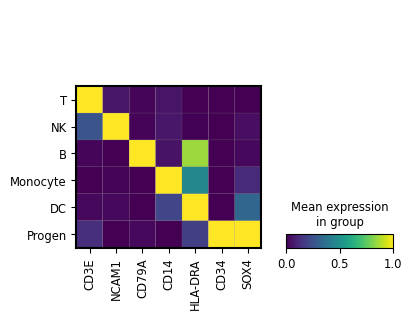

In [26]:
cell_order=['T','NK','B','Monocyte','DC','Progen']
mp=sc.pl.matrixplot(adata[-adata.obs['leiden_MultiVIResolution_2'].isin( qc_filter_cells)],
                        ['CD3E','NCAM1','CD79A','CD14','HLA-DRA','CD34','SOX4'], gene_symbols='name', 
                        groupby='L0_manual',standard_scale='var',
                        categories_order=cell_order,
                        return_fig=True)
mp.show()

## find L1 markers

In [ ]:
lymph_order=['11','13','19','22','27','2','9','10','26', '17',
             '1','23','12','8','16','5',
             '15','20','0',
             '3','4','38','36',
             '29','32']
mye_order=['6', '7','33','21','18','14',   '24',  '41', '30','39']

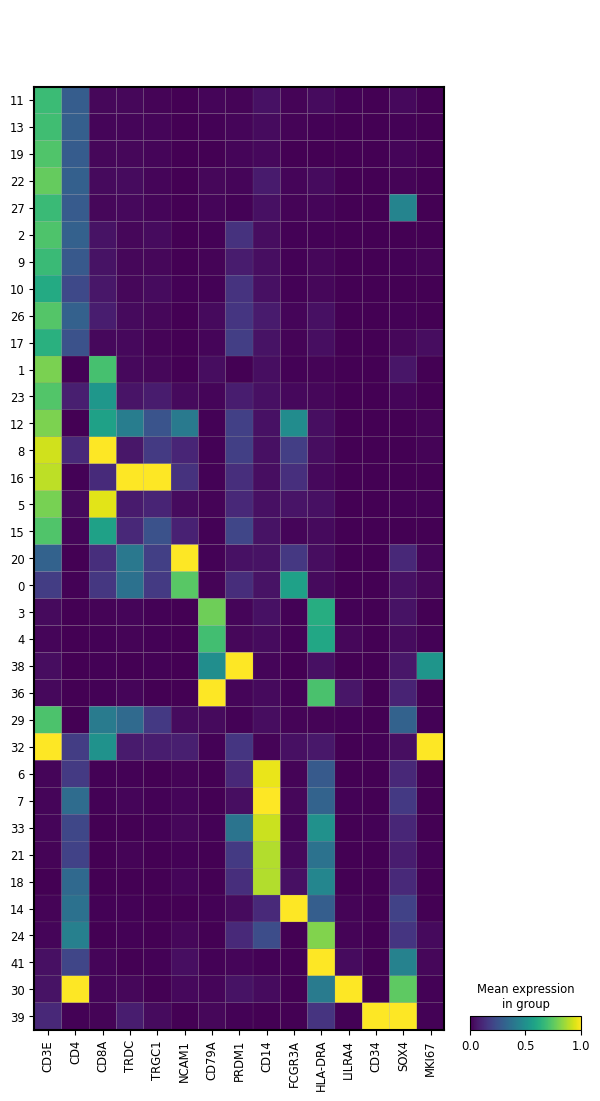

In [8]:
lymph_order=['11','13','19','22','27','2','9','10','26', '17',
             '1','23','12','8','16','5',
             '15','20','0',
             '3','4','38','36',
             '29','32']
mye_order=['6', '7','33','21','18','14',   '24',  '41', '30','39']
cell_order=lymph_order+mye_order
mp=sc.pl.matrixplot(adata[-adata.obs['leiden_MultiVIResolution_2'].isin( qc_filter_cells)],
                        ['CD3E','CD4','CD8A','TRDC','TRGC1','NCAM1','CD79A','PRDM1','CD14',
                         'FCGR3A','HLA-DRA','LILRA4','CD34','SOX4','MKI67'], gene_symbols='name', 
                        groupby='leiden_MultiVIResolution_2',standard_scale='var',
                        categories_order=cell_order,
                        return_fig=True)
mp.show()

In [9]:
L1_cells_R2={
    '0': "NK",
    '1': "CD8T",
    '2': "CD4T",
    '3': "B",
    '4':"B",
    '5':"CD8T",
    '6':"cM",
    '7':"cM",
    '8':"CD8T",
    '9':"CD4T",
    '10':"CD4T",
    '11':"CD4T",
    '12':"CD8T",
    '13':"CD4T",
    '14':"ncM",
    '15':"CD8T",
    '16':"gdT",
    '17':"CD4T",
    '18':"cM",
    '19':"CD4T",
    '20':"NK",
    '21':"cM",
    '22':"CD4T",
    '23':'CD8T',
    '24':'cDC',
    '25':"25",
    '26':'CD4T',
    '27':'CD4T',
    '28':'28',
    '29':'CD8T',
    '30':"pDC",
    '31':'31', #MK?
    '32':'Prolif', #prolif
    '33':'cM',
    '34':'34',
    '35':'35',
    '36':'B',
    '37':'37',
    '38':'Plasma',
    '39':'Progen', #prolif
    '33':'cM',
    '40':'40',
    '41':'cDC',
    '42':'42',
    '43':'43',
    '44':'44',
    '45':'45', #MK?

}
adata.obs['L1_manual']=[ L1_cells_R2[i] for i in adata.obs.leiden_MultiVIResolution_2 ]


/gstore/home/gordom14/miniforge3/envs/scanpy/lib/python3.12/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


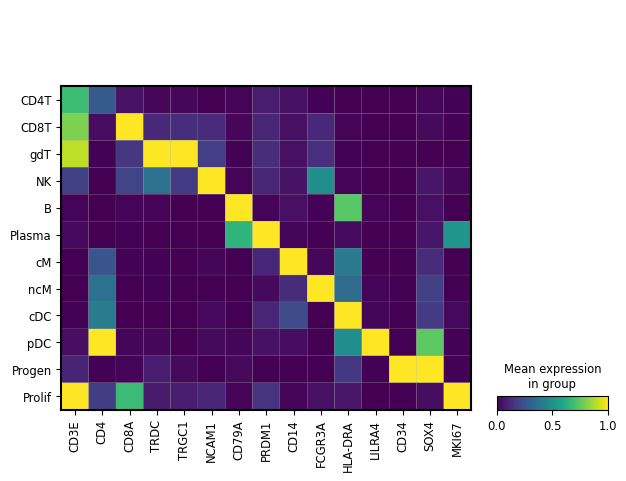

In [10]:
cell_order=['CD4T','CD8T','gdT','NK','B','Plasma','cM','ncM','cDC','pDC','Progen','Prolif']
mp=sc.pl.matrixplot(adata[-adata.obs['leiden_MultiVIResolution_2'].isin( qc_filter_cells)],
                        ['CD3E','CD4','CD8A','TRDC','TRGC1','NCAM1','CD79A','PRDM1','CD14',
                         'FCGR3A','HLA-DRA','LILRA4','CD34','SOX4','MKI67'], gene_symbols='name', 
                        groupby='L1_manual',standard_scale='var',
                        categories_order=cell_order,
                        return_fig=True)
mp.show()

## find L2 markers

/gstore/home/gordom14/miniforge3/envs/scanpy/lib/python3.12/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


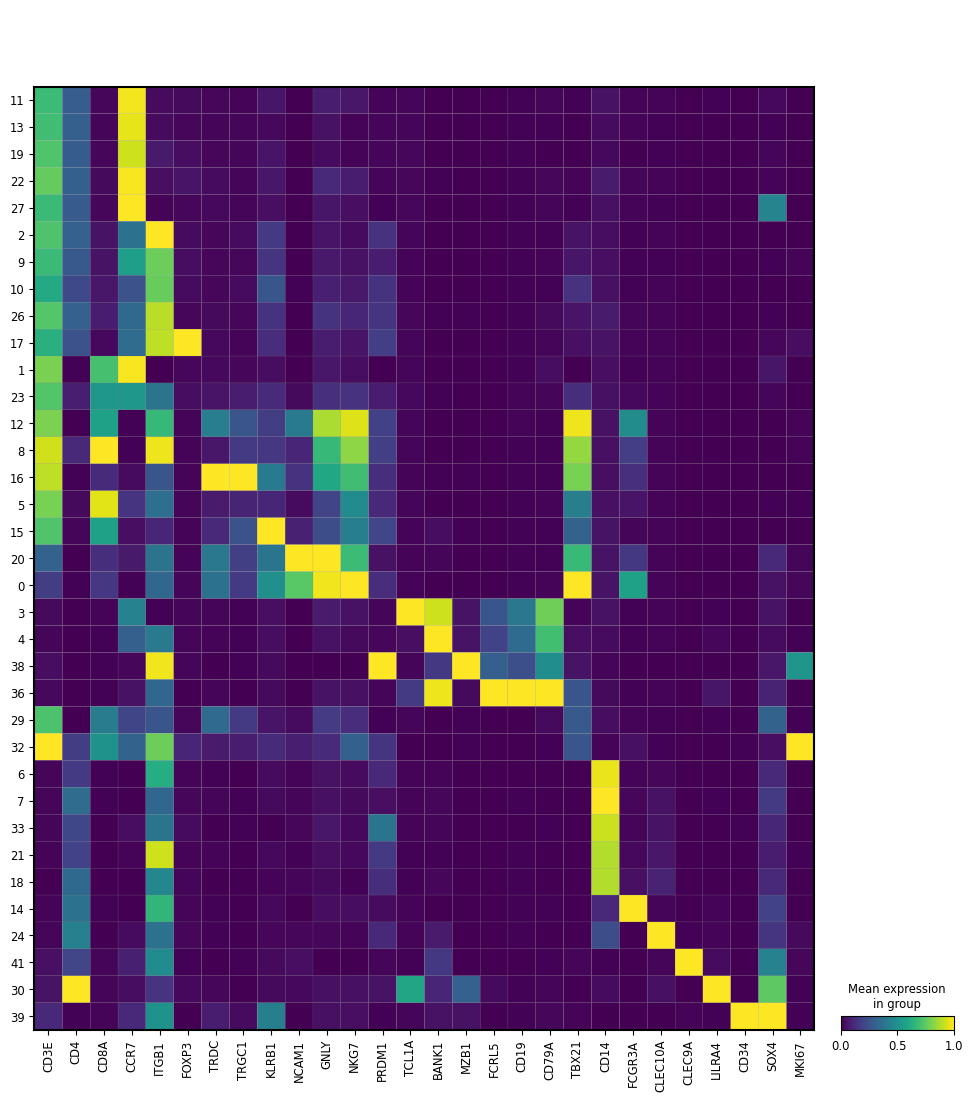

In [11]:
lymph_order=['11','13','19','22','27','2','9','10','26', '17',
             '1','23','12','8','16','5',
             '15','20','0',
             '3','4','38','36',
             '29','32']
mye_order=['6', '7','33','21','18','14',   '24',  '41', '30','39']
cell_order=lymph_order+mye_order
mp=sc.pl.matrixplot(adata[-adata.obs['leiden_MultiVIResolution_2'].isin( qc_filter_cells)],
                        ['CD3E','CD4','CD8A','CCR7','ITGB1','FOXP3','TRDC','TRGC1','KLRB1',
                         'NCAM1','GNLY','NKG7','PRDM1',
                         'TCL1A','BANK1','MZB1','FCRL5','CD19','CD79A','TBX21','CD14','FCGR3A','CLEC10A','CLEC9A','LILRA4',
                         'CD34','SOX4','MKI67'], gene_symbols='name', 
                        groupby='leiden_MultiVIResolution_2',standard_scale='var',
                        categories_order=cell_order,
                        return_fig=True)
mp.show()

In [12]:
## manual Leiden_2
L2_cells_R2={
    '0': "NK_dim",
    '1': "CD8T_Naive",
    '2': "CD4T_Memory",
    '3': "B_Naive",
    '4':"B_Memory",
    '5':"CD8T_Memory",
    '6':"cM",
    '7':"cM",
    '8':"CD8T_Memory",
    '9':"CD4T_Memory",
    '10':"CD4T_Memory",
    '11':"CD4T_Naive",
    '12':"CD8T_Memory",
    '13':"CD4T_Naive",
    '14':"ncM",
    '15':"MAIT",
    '16':"gdT",
    '17':"Treg",
    '18':"cM",
    '19':"CD4T_Naive",
    '20':"NK_bright",
    '21':"cM",
    '22':"CD4T_Naive",
    '23':'CD8T_Memory',
    '24':'cDC2',
    '25':"25",
    '26':'CD4T_Memory',
    '27':'CD4T_Naive',
    '28':'28',
    '29':'CD8T_Memory',
    '30':"pDC",
    '31':'CD8T_platelet', #MK?
    '32':'Prolif', #prolif
    '33':'cM',
    '34':'34',
    '35':'35',
    '36':'B_atypical',
    '37':'37',
    '38':'Plasma',
    '39':'Progen', 
    '40':'40',
    '41':'cDC1',
    '42':'B_lowquality2',
    '43':'prolif_lowquality',
    '44':'B_lowquality1',
    '45':'MK_2', #MK?

}
adata.obs['L2_manual']=[ L2_cells_R2[i] for i in adata.obs.leiden_MultiVIResolution_2 ]


/gstore/home/gordom14/miniforge3/envs/scanpy/lib/python3.12/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/gstore/home/gordom14/miniforge3/envs/scanpy/lib/python3.12/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


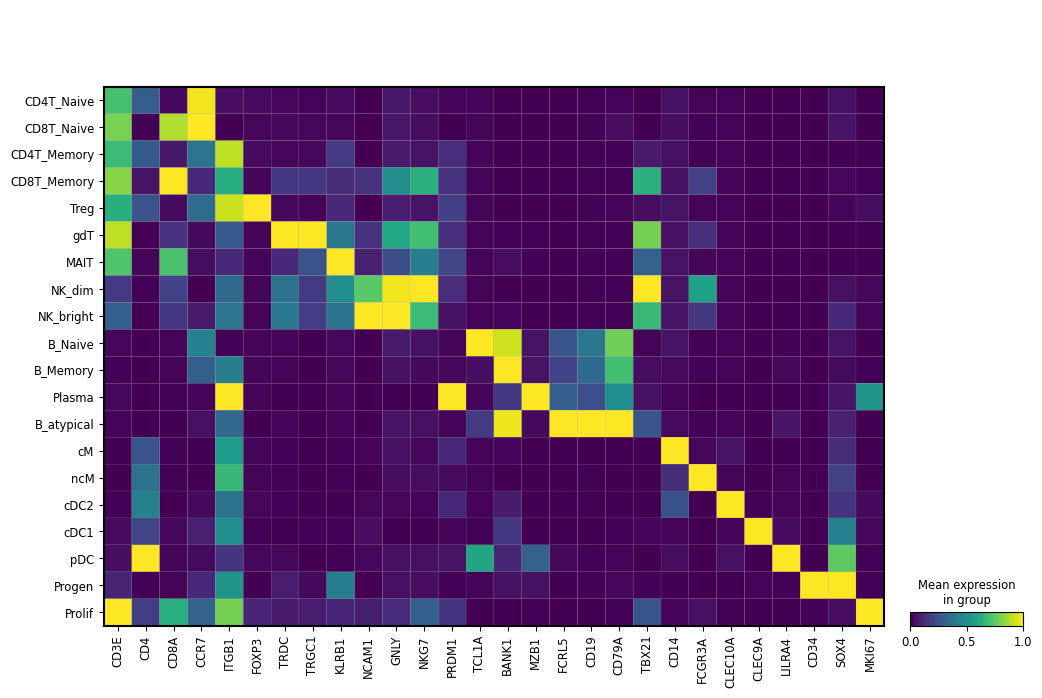

In [13]:
cell_order=['CD4T_Naive','CD8T_Naive','CD4T_Memory','CD8T_Memory','Treg','gdT','MAIT',
            'NK_dim','NK_bright','B_Naive','B_Memory','Plasma','B_atypical','cM','ncM','cDC2','cDC1','pDC','Progen','Prolif']
mp=sc.pl.matrixplot(adata[-adata.obs['leiden_MultiVIResolution_2'].isin( qc_filter_cells)],
                        ['CD3E','CD4','CD8A','CCR7','ITGB1','FOXP3','TRDC','TRGC1','KLRB1',
                         'NCAM1','GNLY','NKG7','PRDM1',
                         'TCL1A','BANK1','MZB1','FCRL5','CD19','CD79A','TBX21','CD14','FCGR3A','CLEC10A','CLEC9A','LILRA4',
                         'CD34','SOX4','MKI67'], gene_symbols='name', 
                        groupby='L2_manual',standard_scale='var',
                        categories_order=cell_order,
                        return_fig=True)
mp.show()

## find L3 markers

/gstore/home/gordom14/miniforge3/envs/scanpy/lib/python3.12/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/gstore/home/gordom14/miniforge3/envs/scanpy/lib/python3.12/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


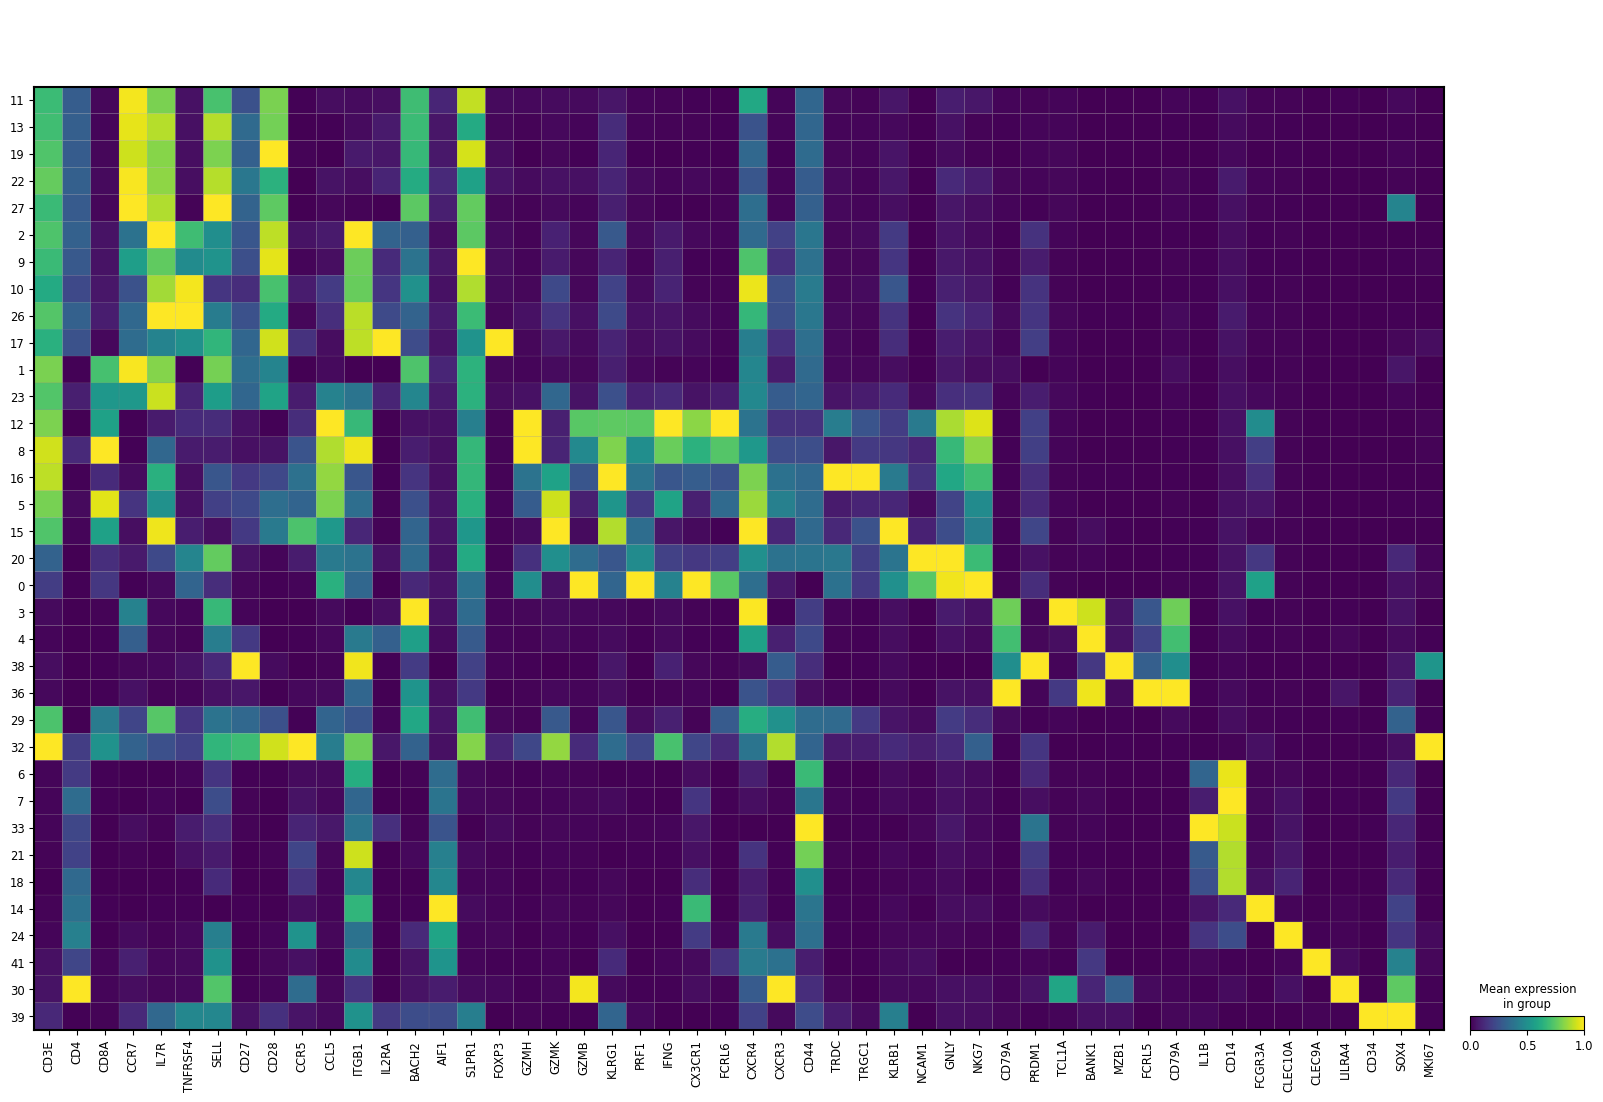

In [14]:
lymph_order=['11','13','19','22','27','2','9','10','26', '17',
             '1','23','12','8','16','5',
             '15','20','0',
             '3','4','38','36',
             '29','32']
mye_order=['6', '7','33','21','18','14',   '24',  '41', '30','39']
cell_order=lymph_order+mye_order
mp=sc.pl.matrixplot(adata[-adata.obs['leiden_MultiVIResolution_2'].isin( qc_filter_cells)],
                        ['CD3E','CD4','CD8A','CCR7','IL7R','TNFRSF4','SELL',
                         'CD27','CD28','CCR5','CCL5','ITGB1','IL2RA','BACH2','AIF1','S1PR1',
                         'FOXP3','GZMH','GZMK','GZMB','KLRG1','PRF1','IFNG','CX3CR1','FCRL6','CXCR4','CXCR3','CD44',
                         'TRDC','TRGC1','KLRB1',
                         'NCAM1','GNLY','NKG7','CD79A','PRDM1',
                         'TCL1A','BANK1','MZB1','FCRL5','CD79A','IL1B','CD14','FCGR3A','CLEC10A','CLEC9A','LILRA4',
                         'CD34','SOX4','MKI67'], gene_symbols='name', 
                        groupby='leiden_MultiVIResolution_2',standard_scale='var',
                        categories_order=cell_order,
                        return_fig=True)
mp.show()

In [15]:
## manual Leiden_2
L3_cells_R2={
    '0': "NK_dim",
    '1': "CD8T_Naive",
    '2': "CD4T_CM",
    '3': "B_Naive",
    '4':"B_Memory",
    '5':"CD8T_GZMK",
    '6':"cM",
    '7':"cM",
    '8':"CD8T_GZMH",
    '9':"CD4T_CM",
    '10':"CD4T_EM",
    '11':"CD4T_Naive",
    '12':"CD8T_GZMH",
    '13':"CD4T_Naive",
    '14':"ncM",
    '15':"MAIT",
    '16':"gdT",
    '17':"Treg",
    '18':"cM",
    '19':"CD4T_Naive",
    '20':"NK_bright",
    '21':"cM",
    '22':"CD4T_Naive",
    '23':'CD8T_GZMK',
    '24':'cDC2',
    '25':"25",
    '26':'CD4T_EM',
    '27':'CD4T_Naive_SOX4',
    '28':'28',
    '29':'CD8T_progen',
    '30':"pDC",
    '31':'CD8T_platelet', #MK?
    '32':'Prolif', #prolif
    '33':'cM_IL1B',
    '34':'34',
    '35':'35',
    '36':'B_atypical',
    '37':'37',
    '38':'Plasma',
    '39':'Progen', 
    '40':'40',
    '41':'cDC1',
    '42':'B_lowquality2',
    '43':'prolif_lowquality',
    '44':'B_lowquality1',
    '45':'MK_2', #MK?

}
adata.obs['L3_manual']=[ L3_cells_R2[i] for i in adata.obs.leiden_MultiVIResolution_2 ]

/gstore/home/gordom14/miniforge3/envs/scanpy/lib/python3.12/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/gstore/home/gordom14/miniforge3/envs/scanpy/lib/python3.12/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/gstore/home/gordom14/miniforge3/envs/scanpy/lib/python3.12/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


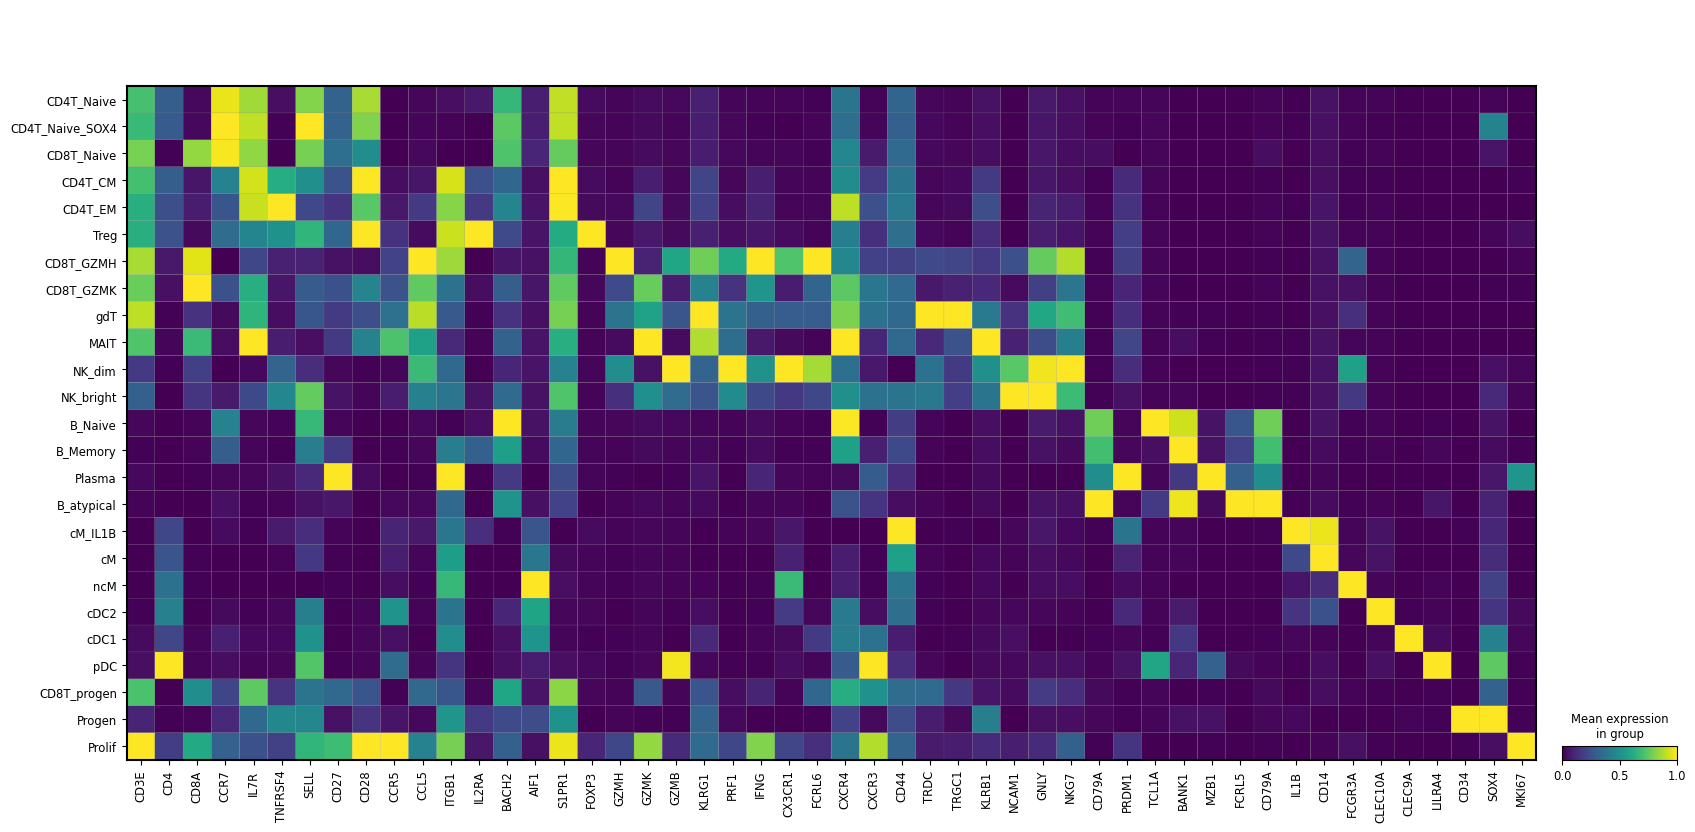

In [16]:
 
cell_order=[ 'CD4T_Naive','CD4T_Naive_SOX4', 'CD8T_Naive', 'CD4T_CM',#'CD8T_CM_ITGA4',
            'CD4T_EM','Treg','CD8T_GZMH','CD8T_GZMK',
            'gdT','MAIT','NK_dim','NK_bright','B_Naive','B_Memory','Plasma','B_atypical',
            'cM_IL1B','cM','ncM','cDC2','cDC1','pDC','CD8T_progen','Progen','Prolif'
            ]

mp=sc.pl.matrixplot(adata[-adata.obs['leiden_MultiVIResolution_2'].isin( qc_filter_cells)],
                        ['CD3E','CD4','CD8A','CCR7','IL7R','TNFRSF4','SELL',
                         'CD27','CD28','CCR5','CCL5','ITGB1','IL2RA','BACH2','AIF1','S1PR1',
                         'FOXP3','GZMH','GZMK','GZMB','KLRG1','PRF1','IFNG','CX3CR1','FCRL6','CXCR4','CXCR3','CD44',
                         'TRDC','TRGC1','KLRB1',
                         'NCAM1','GNLY','NKG7','CD79A','PRDM1',
                         'TCL1A','BANK1','MZB1','FCRL5','CD79A','IL1B','CD14','FCGR3A','CLEC10A','CLEC9A','LILRA4',
                         'CD34','SOX4','MKI67'], gene_symbols='name', 
                        groupby='L3_manual',standard_scale='var',
                        categories_order=cell_order,
                        return_fig=True)
mp.show()

## save outputs

In [ ]:

## manual Leiden_2
L0_cells_R2={
    '0': "NK",
    '1': "T",
    '2': "T",
    '3': "B",
    '4':"B",
    '5':"T",
    '6':"Monocyte",
    '7':"Monocyte",
    '8':"T",
    '9':"T",
    '10':"T",
    '11':"T",
    '12':"T",
    '13':"T",
    '14':"Monocyte",
    '15':"T",
    '16':"T",
    '17':"T",
    '18':"Monocyte",
    '19':"T",
    '20':"NK",
    '21':"Monocyte",
    '22':"T",
    '23':'T',
    '24':'DC',
    '25':"25",
    '26':'T',
    '27':'T',
    '28':'28',
    '29':'T',
    '30':"DC",
    '31':'T',
    '32':'T',
    '33':'Monocyte',
    '34':'34',
    '35':'35',
    '36':'B',
    '37':'37',
    '38':'B',
    '39':'Progen',
    '40':'40',
    '41':'DC',
    '42':'42',
    '43':'43',
    '44':'44',
    '45':'45'

}
adata.obs['L0_manual']=[ L0_cells_R2[i] for i in adata.obs.leiden_MultiVIResolution_2 ]

L1_cells={
    '0':'CD4T',
    '1':'CD4T',
    '2':'NK',
    '3':'cM',
    '4':'CD8T',
    '5':'CD8T',
    '6':'B',
    '7':'cM',
    '8':'B',
    '9':'CD8T',
    '10':'ncM',
    '11':'CD8T',
    '12':'CD4T',
    '13':'gdT',
    '14':'CD4T',
    '15':'CD8T',
    '16':'16',
    '17':'cDC',
    '18':'NK',
    '19':'pDC',
    '20':'20',
    '21':'21',
    '22':'cM',
    '23':'23',
    '24':'24',
    '25':'25',
    '26':'B',
    '27':'27',
    '28':'cDC',
    '29':'29',
    '30':'30',
    '31':'31'
}
## manual Leiden_2
L1_cells_R2={
    '0': "NK",
    '1': "CD8T",
    '2': "CD4T",
    '3': "B",
    '4':"B",
    '5':"CD8T",
    '6':"cM",
    '7':"cM",
    '8':"CD8T",
    '9':"CD4T",
    '10':"CD4T",
    '11':"CD4T",
    '12':"CD8T",
    '13':"CD4T",
    '14':"ncM",
    '15':"CD8T",
    '16':"gdT",
    '17':"CD4T",
    '18':"cM",
    '19':"CD4T",
    '20':"NK",
    '21':"cM",
    '22':"CD4T",
    '23':'CD8T',
    '24':'cDC',
    '25':"25",
    '26':'CD4T',
    '27':'CD4T',
    '28':'28',
    '29':'CD8T',
    '30':"pDC",
    '31':'31', #MK?
    '32':'Prolif', #prolif
    '33':'cM',
    '34':'34',
    '35':'35',
    '36':'B',
    '37':'37',
    '38':'Plasma',
    '39':'Progen', #prolif
    '33':'cM',
    '40':'40',
    '41':'cDC',
    '42':'42',
    '43':'43',
    '44':'44',
    '45':'45', #MK?

}
adata.obs['L1_manual']=[ L1_cells_R2[i] for i in adata.obs.leiden_MultiVIResolution_2 ]

#adata.obs['L1_manual']=[ L1_cells[i] for i in adata.obs.leiden_MultiVIResolution_1 ]

question_cells=['13','16', '20','21','23', '24', '26', '27', '29', '31']

## manual Leiden_2
L2_cells_R2={
    '0': "NK_dim",
    '1': "CD8T_Naive",
    '2': "CD4T_Memory",
    '3': "B_Naive",
    '4':"B_Memory",
    '5':"CD8T_Memory",
    '6':"cM",
    '7':"cM",
    '8':"CD8T_Memory",
    '9':"CD4T_Memory",
    '10':"CD4T_Memory",
    '11':"CD4T_Naive",
    '12':"CD8T_Memory",
    '13':"CD4T_Naive",
    '14':"ncM",
    '15':"MAIT",
    '16':"gdT",
    '17':"Treg",
    '18':"cM",
    '19':"CD4T_Naive",
    '20':"NK_bright",
    '21':"cM",
    '22':"CD4T_Naive",
    '23':'CD8T_Memory',
    '24':'cDC2',
    '25':"25",
    '26':'CD4T_Memory',
    '27':'CD4T_Naive',
    '28':'28',
    '29':'CD8T_Memory',
    '30':"pDC",
    '31':'CD8T_platelet', #MK?
    '32':'Prolif', #prolif
    '33':'cM',
    '34':'34',
    '35':'35',
    '36':'B_atypical',
    '37':'37',
    '38':'Plasma',
    '39':'Progen', 
    '40':'40',
    '41':'cDC1',
    '42':'B_lowquality2',
    '43':'prolif_lowquality',
    '44':'B_lowquality1',
    '45':'MK_2', #MK?

}
adata.obs['L2_manual']=[ L2_cells_R2[i] for i in adata.obs.leiden_MultiVIResolution_2 ]

#GZMK CD8T is EM
## manual Leiden_2
L3_cells_R2={
    '0': "NK_dim",
    '1': "CD8T_Naive",
    '2': "CD4T_CM",
    '3': "B_Naive",
    '4':"B_Memory",
    '5':"CD8T_GZMK",
    '6':"cM",
    '7':"cM",
    '8':"CD8T_GZMH",
    '9':"CD4T_CM",
    '10':"CD4T_EM",
    '11':"CD4T_Naive",
    '12':"CD8T_GZMH",
    '13':"CD4T_Naive",
    '14':"ncM",
    '15':"MAIT",
    '16':"gdT",
    '17':"Treg",
    '18':"cM",
    '19':"CD4T_Naive",
    '20':"NK_bright",
    '21':"cM",
    '22':"CD4T_Naive",
    '23':'CD8T_GZMK',
    '24':'cDC2',
    '25':"25",
    '26':'CD4T_EM',
    '27':'CD4T_Naive_SOX4',
    '28':'28',
    '29':'CD8T_progen',
    '30':"pDC",
    '31':'CD8T_platelet', #MK?
    '32':'Prolif', #prolif
    '33':'cM_IL1B',
    '34':'34',
    '35':'35',
    '36':'B_atypical',
    '37':'37',
    '38':'Plasma',
    '39':'Progen', 
    '40':'40',
    '41':'cDC1',
    '42':'B_lowquality2',
    '43':'prolif_lowquality',
    '44':'B_lowquality1',
    '45':'MK_2', #MK?

}
adata.obs['L3_manual']=[ L3_cells_R2[i] for i in adata.obs.leiden_MultiVIResolution_2 ]
basic_qc_filt=['25','28','31','34','37','40','44','45']
qc_filter_cells=['25','28','31','34','37','40','44','45','42','43','35']
#35,42,43 are almost enirely made of donors CUPP_311 and CUPP_301 so likely issues with those two samples


In [ ]:
adata.write_h5ad('/gstore/data/ctgbioinfo/gordom14/ICC/data/current_objects/jan2025/MultiVI_posttraining_RNA_Celltypist_VaryingClusteringResolution_manual_annots.h5ad')

In [ ]:
cellannots=adata.obs[['L0_manual','L1_manual','L2_manual','L3_manual']]
cellannots.index=[ i.replace(';','#') for i in cellannots.index ]
cellannots.to_csv('/gstore/data/ctgbioinfo/gordom14/ICC/data/current_objects/jan2025/MultiVI_posttraining_RNA_Celltypist_VaryingClusteringResolution_manual_annots_celltypes.csv')